# Energy Efficiency of Residential Buildings
**EE 311 Project:** predicting the **heating load** and **cooling load** of a building from 8 design parameters.

- **Dataset:** UCI *Energy Efficiency* (`data/ENB2012_data.csv`): 768 simulated buildings, 8 inputs, 2 outputs.
- **Reference article:** A. Tsanas and A. Xifara, "Accurate quantitative estimation of energy performance of residential
  buildings using statistical machine learning tools," *Energy and Buildings*, vol. 49, pp. 560–567, 2012.

**Notebook outline** (follows the ML Project Checklist from the textbook):
1. Setup
2. Get the data
3. Explore the data
4. Prepare the data
5. Shortlist promising models (same evaluation as the article)
6. Fine-tune the best models
7. Testing on unseen building shapes (grouped CV)
8. Which inputs matter most?
9. Next steps

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, spearmanr

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import HuberRegressor, LinearRegression
from sklearn.model_selection import (
    GroupKFold, KFold, LeaveOneGroupOut, RandomizedSearchCV, RepeatedKFold, cross_val_predict, cross_validate,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

DATA_FILE = "data/ENB2012_data.csv"  # relative to this notebook's folder (src/)
RANDOM_STATE = 42  # fixed seed, so every run gives the same results
N_REPEATS = 10     # how many times 10-fold CV is repeated (the article uses 100; 10 is faster)
N_ITER = 40        # how many random settings the hyperparameter search tries per model (section 6)
RUN_NESTED_CHECK = True  # section 6.3 takes a few minutes; set to False to skip it

# Plot colors: heating = orange, cooling = blue, inputs = gray
COLORS = {"heating_load": "#eb6834", "cooling_load": "#2a78d6"}
INPUT_COLOR = "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

## 2. Get the data
The CSV was exported from Excel with European number settings, so columns are separated by `;`
and decimals use `,` (e.g. `0,98`). We also replace the short column names (X1…X8, Y1, Y2) with readable ones.

In [2]:
COLUMN_NAMES = {
    "X1": "relative_compactness",
    "X2": "surface_area",
    "X3": "wall_area",
    "X4": "roof_area",
    "X5": "overall_height",
    "X6": "orientation",
    "X7": "glazing_area",
    "X8": "glazing_area_distribution",
    "Y1": "heating_load",
    "Y2": "cooling_load",
}

df = pd.read_csv(DATA_FILE, sep=";", decimal=",")
df = df.dropna(how="all")  # safety: drop fully empty rows (Excel exports sometimes add them)
df = df.rename(columns=COLUMN_NAMES)

FEATURES = list(COLUMN_NAMES.values())[:8]
TARGETS = ["heating_load", "cooling_load"]

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (768, 10)


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 3. Explore the data
### 3.1 Quick look

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T.round(2)

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
relative_compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98
surface_area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50
wall_area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50
roof_area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50
overall_height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00
orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00
glazing_area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40
glazing_area_distribution,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00
heating_load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10
cooling_load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03


Number of distinct values per column. These match Table 1 of the article.

In [4]:
df.nunique().to_frame("distinct_values")

,distinct_values
relative_compactness,12
surface_area,12
wall_area,7
roof_area,4
overall_height,2
orientation,4
glazing_area,4
glazing_area_distribution,6
heating_load,586
cooling_load,636


### 3.2 Distribution of each variable (article Fig. 1)

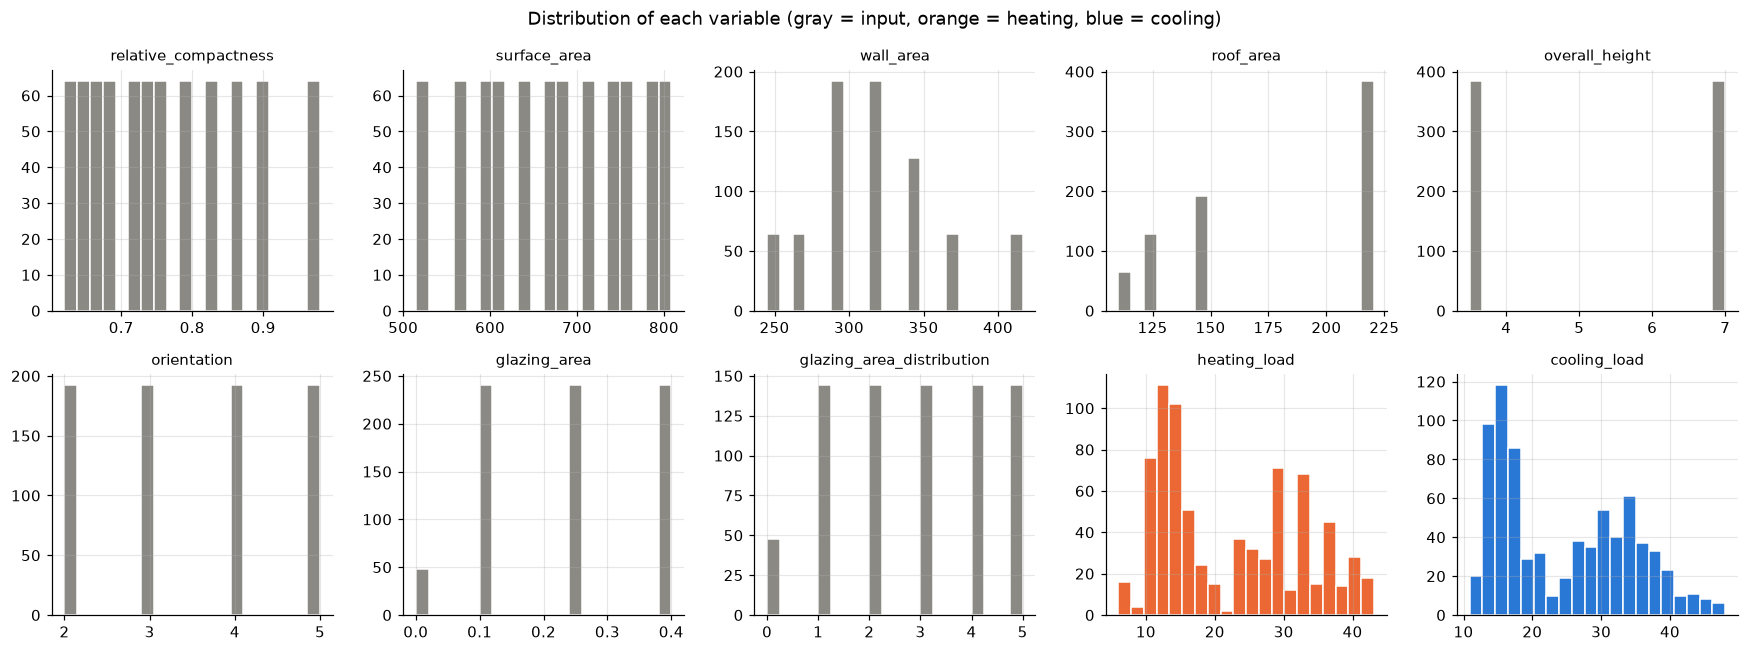

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, column in zip(axes.flat, df.columns):
    ax.hist(df[column], bins=20, color=COLORS.get(column, INPUT_COLOR), edgecolor="white")
    ax.set_title(column, fontsize=10)
fig.suptitle("Distribution of each variable (gray = input, orange = heating, blue = cooling)")
plt.tight_layout()
plt.show()

**Observations**
- No variable is normally distributed. Every input takes only a few distinct values (2 to 12),
  because the buildings come from a designed simulation (12 shapes × glazing options × 4 orientations).
- Both loads are **bimodal** (two groups), which comes from the two building heights (3.5 m and 7 m).

### 3.3 Each input vs. the outputs (article Fig. 2)

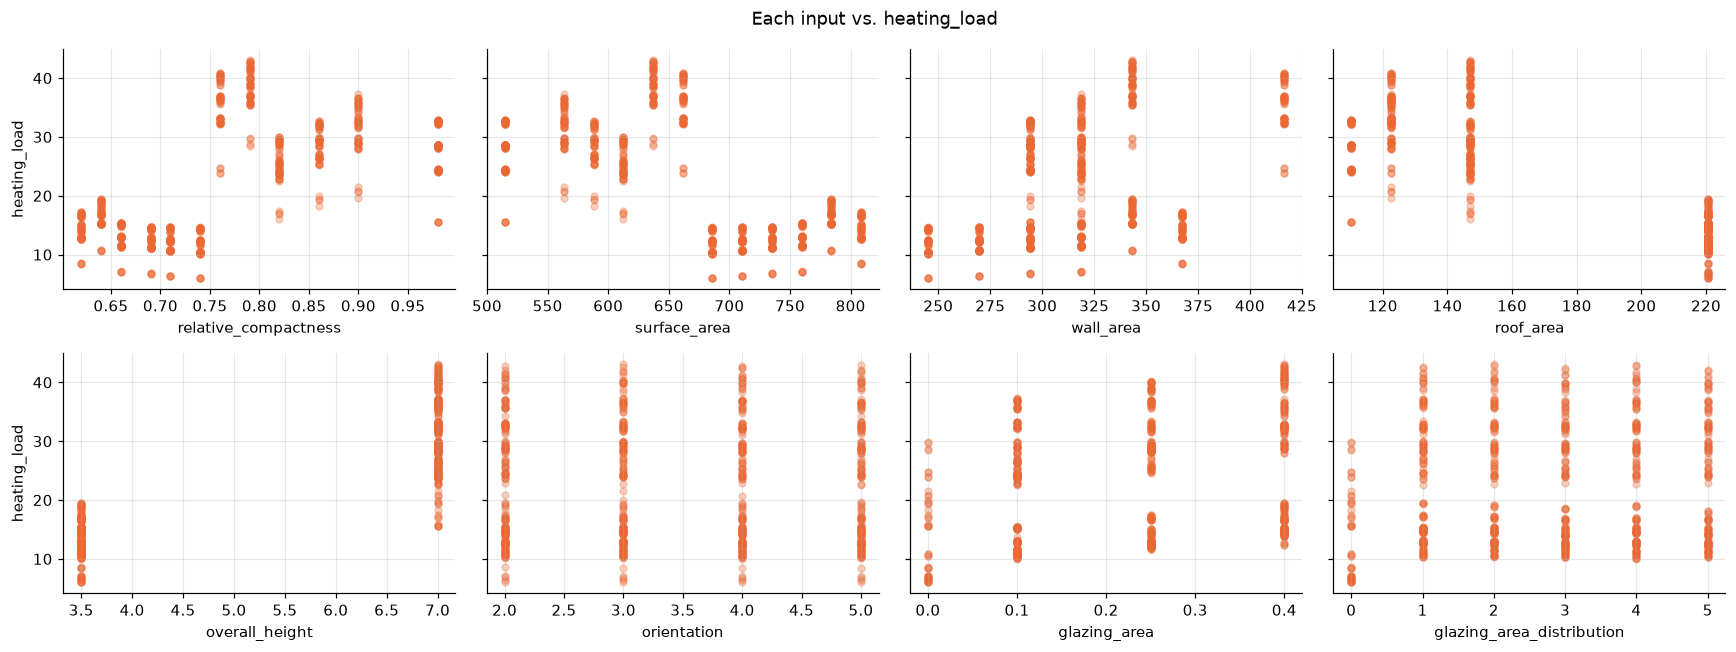

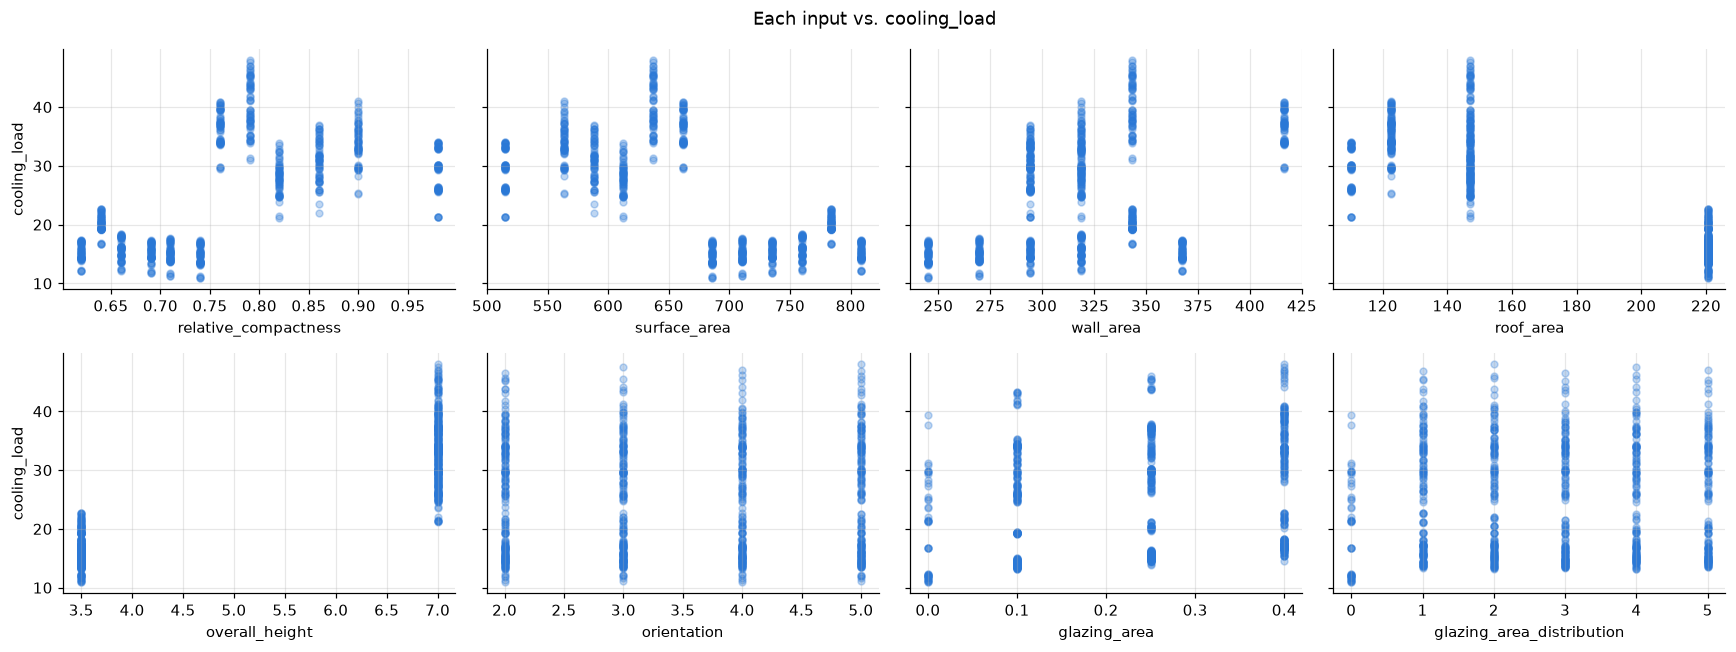

In [6]:
for target in TARGETS:
    fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
    for ax, feature in zip(axes.flat, FEATURES):
        ax.scatter(df[feature], df[target], s=20, alpha=0.3, color=COLORS[target])
        ax.set_xlabel(feature)
    for ax in axes[:, 0]:
        ax.set_ylabel(target)
    fig.suptitle(f"Each input vs. {target}")
    plt.tight_layout()
    plt.show()

### 3.4 How strongly is each input related to each output? (article Tables 2–3)
- **Spearman correlation** (ρ, from −1 to 1): measures monotonic relationships. Used because the data is not normal.
- **Mutual information**: detects *any* relationship (not just monotonic). Higher = stronger.
  The article rescales it to 0–1; here it is unscaled, so compare the **ranking**, not the exact values.

In [7]:
def association_table(target):
    """Spearman correlation and mutual information of every input with one target."""
    mutual_info = mutual_info_regression(
        df[FEATURES], df[target], discrete_features=True, random_state=RANDOM_STATE
    )
    rows = []
    for feature, mi in zip(FEATURES, mutual_info):
        rho, p_value = spearmanr(df[feature], df[target])
        rows.append({"feature": feature, "mutual_info": mi, "spearman_rho": rho, "p_value": p_value})
    return pd.DataFrame(rows).sort_values("mutual_info", ascending=False).round(3)


for target in TARGETS:
    print(target)
    display(association_table(target))

heating_load


,feature,mutual_info,spearman_rho,p_value
0,relative_compactness,1.721,0.622,0.000
1,surface_area,1.721,-0.622,0.000
2,wall_area,1.110,0.471,0.000
3,roof_area,0.926,-0.804,0.000
6,glazing_area,0.701,0.323,0.000
4,overall_height,0.664,0.861,0.000
7,glazing_area_distribution,0.219,0.068,0.058
5,orientation,0.000,-0.004,0.908


cooling_load


,feature,mutual_info,spearman_rho,p_value
0,relative_compactness,1.419,0.651,0.000
1,surface_area,1.419,-0.651,0.000
3,roof_area,0.876,-0.803,0.000
2,wall_area,0.870,0.416,0.000
6,glazing_area,0.732,0.289,0.000
4,overall_height,0.682,0.865,0.000
7,glazing_area_distribution,0.147,0.046,0.198
5,orientation,0.000,0.018,0.626


### 3.5 Correlation between all variables (article Table 4)

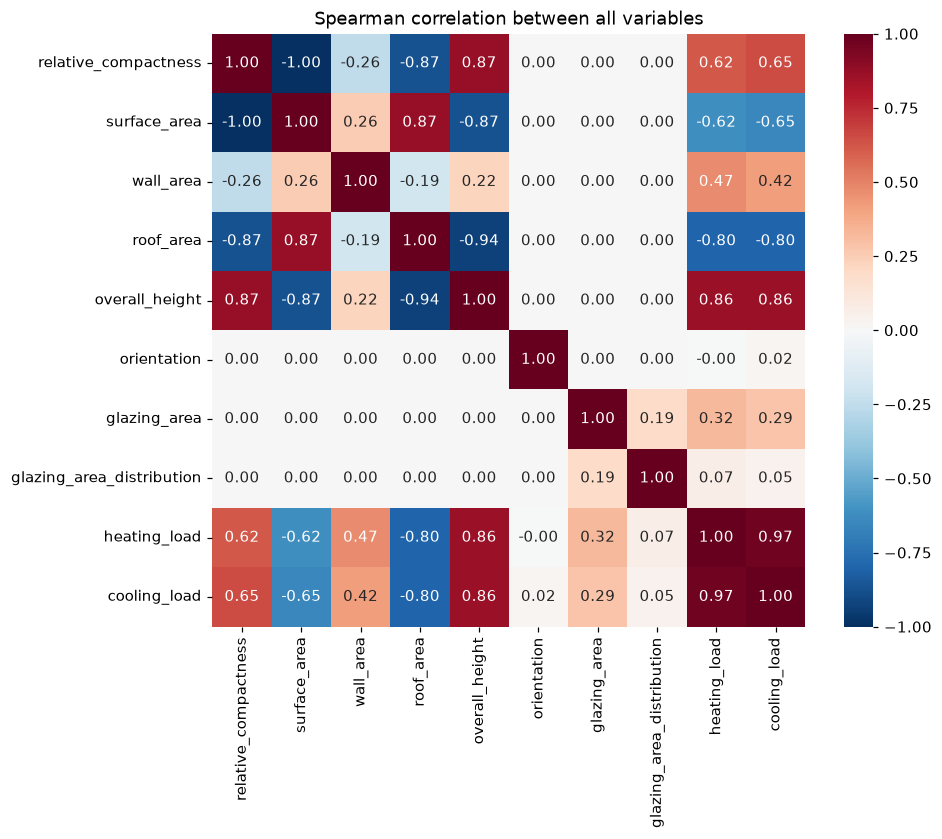

In [8]:
correlation = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)
ax.grid(False)
ax.set_title("Spearman correlation between all variables")
plt.show()

**Observations**
- `relative_compactness` and `surface_area` have ρ = −1: they carry the **same information**
  (all buildings have the same volume). `roof_area` and `overall_height` are also strongly related (ρ ≈ −0.94).
  This redundancy is a problem for linear models (unstable coefficients), but not for tree-based models.
- `orientation` is not correlated with any other variable, including both outputs. This does not mean it has no
  effect: see §3.6.
- The two outputs are very strongly related to each other (ρ ≈ 0.97).

### 3.6 Does orientation matter?
The correlations above say that orientation is unrelated to both loads. But a correlation only detects effects that
go in one direction (for example: a higher code gives a higher load). Here we look directly: for each group of
4 buildings that differ **only** in orientation (same shape and glazing), how much does the load change?

In [9]:
# For each group of 4 buildings with the same shape and glazing: largest minus smallest load
same_but_orientation = df.groupby(["relative_compactness", "glazing_area", "glazing_area_distribution"])[TARGETS]
spread = (same_but_orientation.max() - same_but_orientation.min()).reset_index()

spread_by_shape = spread.groupby("relative_compactness")[TARGETS].median()
spread_by_shape.insert(0, "overall_height", df.groupby("relative_compactness")["overall_height"].first())
print("Median change in load when only the orientation changes, for each shape:")
display(spread_by_shape.sort_index(ascending=False).round(2))

print("Example: shape 0.79 without windows")
display(df.loc[(df["relative_compactness"] == 0.79) & (df["glazing_area"] == 0), ["orientation"] + TARGETS])

Median change in load when only the orientation changes, for each shape:


,overall_height,heating_load,cooling_load
relative_compactness,,,
0.98,7.0,0.42,0.55
0.90,7.0,1.57,4.90
0.86,7.0,1.43,6.09
0.82,7.0,1.25,3.94
0.79,7.0,1.48,8.93
0.76,7.0,0.83,0.86
0.74,3.5,0.15,0.36
0.71,3.5,0.20,0.54
0.69,3.5,0.21,0.58


Example: shape 0.79 without windows


,orientation,heating_load,cooling_load
16,2,28.52,37.73
17,3,29.90,31.27
18,4,29.63,30.93
19,5,28.75,39.44


**Observations**
- For heating, orientation changes the load very little (median change at most about 1.6 for every shape).
  For cooling, the same holds for 8 of the 12 shapes (median change below 0.9).
- But for four two-storey shapes (0.90, 0.86, 0.82 and 0.79), orientation changes the **cooling** load a lot:
  the median change is about 4 to 9. For shape 0.79 without windows, the cooling load goes from about 31 to 39
  depending on the orientation.
- For shape 0.79 the effect does not go in one direction (codes 2 and 5 give high cooling loads, codes 3 and 4
  low ones), so the correlation stays close to zero even though orientation matters. Treating orientation as a
  category (one-hot encoding) may therefore help the linear models (§9).
- This also matters for §7: buildings that differ only in orientation are near-copies for most shapes, but not
  for the cooling load of these four shapes.

## 4. Prepare the data
The data is already clean: no missing values, no text columns, no duplicate rows. So the only preparation is:
- split the columns into inputs `X` and outputs `y`
- **scale** the inputs for models that need it (linear, k-NN, SVR). The scaler sits *inside* a pipeline,
  so in cross-validation it is fitted on the training folds only (no information leaks from the test fold).

In [10]:
X = df[FEATURES]
y = df[TARGETS]

## 5. Shortlist promising models
We use the **same evaluation as the article**: 10-fold cross-validation repeated several times,
reporting three errors on the test folds:
- **MAE**: mean absolute error (in the same unit as the load)
- **MSE**: mean squared error (punishes large errors more)
- **MRE**: mean relative error, in % of the true value

The article compares a robust linear model (IRLS) with a random forest. Our closest match to IRLS is
the robust Huber regressor. We add four more models.
Settings are reasonable defaults, **not tuned yet** (tuning is a later step).

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Robust Linear (Huber)": make_pipeline(StandardScaler(), HuberRegressor(max_iter=1000)),
    "k-Nearest Neighbors": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR(C=100)),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = RepeatedKFold(n_splits=10, n_repeats=N_REPEATS, random_state=RANDOM_STATE)

# scikit-learn names for our three errors (it returns them as negative numbers)
SCORING = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "MRE": "neg_mean_absolute_percentage_error",
}


def evaluate(model, target, cv=cv, groups=None):
    """Cross-validated errors of one model: by default repeated 10-fold CV, as in the article.
    Returns the mean and std of each error over all test folds. `groups` is only needed for grouped CV (section 7)."""
    scores = cross_validate(model, X, y[target], cv=cv, groups=groups, scoring=SCORING, n_jobs=-1)
    result = {}
    for metric in SCORING:
        errors = -scores[f"test_{metric}"]  # make the errors positive again
        if metric == "MRE":
            errors = errors * 100  # as a percentage, like the article
        result[metric] = errors.mean()
        result[f"{metric}_std"] = errors.std()
    return result

In [12]:
rows = []
for target in TARGETS:
    for name, model in models.items():
        rows.append({"target": target, "model": name, **evaluate(model, target)})

results = pd.DataFrame(rows).round(2)

for target in TARGETS:
    print(target)
    display(results[results["target"] == target].drop(columns="target").sort_values("MAE"))

heating_load


,model,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
4,Random Forest,0.31,0.04,0.22,0.06,1.33,0.18
5,Gradient Boosting,0.34,0.04,0.22,0.06,1.53,0.21
3,Support Vector Regression,0.55,0.08,0.63,0.21,2.82,0.40
2,k-Nearest Neighbors,1.42,0.20,4.92,1.26,6.32,0.83
1,Robust Linear (Huber),2.03,0.25,8.87,1.89,9.42,1.01
0,Linear Regression,2.09,0.24,8.68,1.77,9.85,0.96


cooling_load


,model,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
10,Random Forest,0.98,0.14,2.62,0.69,3.37,0.40
11,Gradient Boosting,1.02,0.13,2.28,0.56,3.69,0.36
9,Support Vector Regression,1.13,0.19,3.18,1.09,4.39,0.59
8,k-Nearest Neighbors,1.66,0.24,6.30,2.01,6.61,0.77
7,Robust Linear (Huber),2.20,0.30,10.67,2.99,8.43,0.83
6,Linear Regression,2.27,0.27,10.34,2.72,8.99,0.78


**Article results for comparison** (Tables 5–7, 10-fold CV repeated 100 times, mean ± std):

| Error | IRLS heating | RF heating | IRLS cooling | RF cooling |
|---|---|---|---|---|
| MAE | 2.14 ± 0.24 | 0.51 ± 0.11 | 2.21 ± 0.28 | 1.42 ± 0.25 |
| MSE | 9.87 ± 2.41 | 1.03 ± 0.54 | 11.46 ± 3.63 | 6.59 ± 1.56 |
| MRE (%) | 10.09 ± 1.01 | 2.18 ± 0.64 | 9.41 ± 0.80 | 4.62 ± 0.70 |

Our `_std` columns are the spread over all individual test folds. The article does not say exactly how its ± is
computed, but its values are on the same scale as ours.

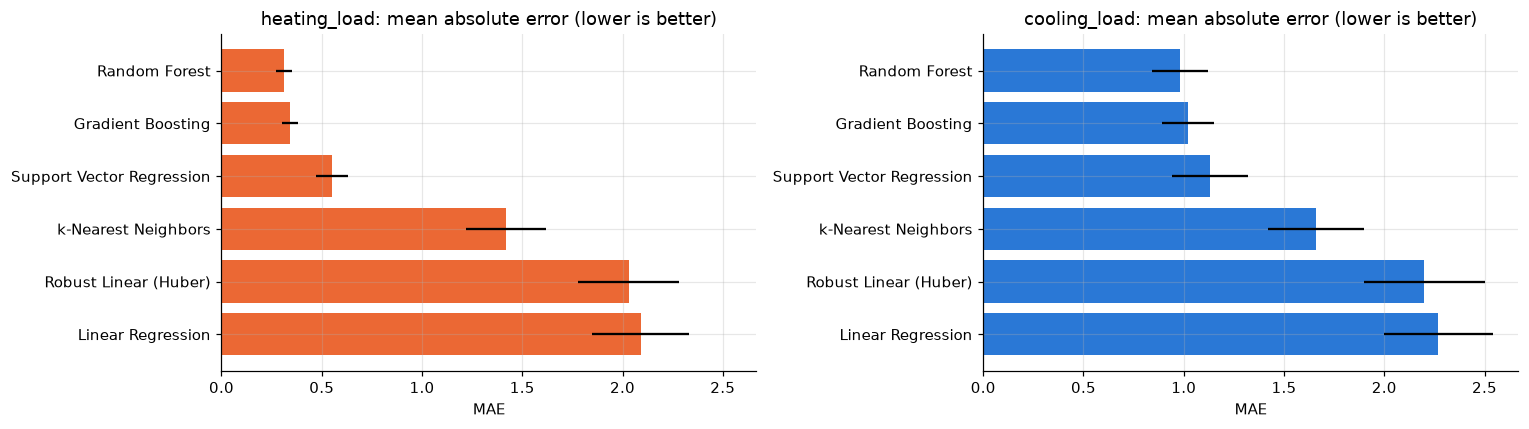

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, target in zip(axes, TARGETS):
    table = results[results["target"] == target].sort_values("MAE", ascending=False)
    ax.barh(table["model"], table["MAE"], xerr=table["MAE_std"], color=COLORS[target])
    ax.set_title(f"{target}: mean absolute error (lower is better)")
    ax.set_xlabel("MAE")
plt.tight_layout()
plt.show()

## 6. Fine-tune the best models
The three best models from §5 (random forest, gradient boosting and SVR) used default settings.
Here we search for better **hyperparameters**: settings chosen before training, such as the number of trees.

**How:** `RandomizedSearchCV` tries `N_ITER` random combinations from the ranges below. Each combination is
scored by its MAE with 5-fold cross-validation, and the best one is kept. Each load gets its own search,
because the best settings can differ between heating and cooling. The search uses 5 folds (instead of 10)
to stay fast.

| Model | Hyperparameter | What it controls |
|---|---|---|
| Random forest | `max_features` | how many inputs each split may choose from |
| | `min_samples_leaf` | smallest number of buildings in a leaf (larger = smoother predictions) |
| | `max_depth` | maximum depth of each tree |
| | `bootstrap` | whether each tree sees a random resample of the data, or all of it |
| Gradient boosting | `n_estimators` | number of trees, added one after another |
| | `learning_rate` | how much each new tree corrects the previous ones |
| | `max_depth` | size of each tree (deeper = more interactions between inputs) |
| | `subsample` | fraction of the data each tree is trained on |
| | `min_samples_leaf` | smallest number of buildings in a leaf |
| SVR | `C` | how strongly errors are penalized (larger = follows the data more closely) |
| | `gamma` | how far the influence of one building reaches (larger = more local) |
| | `epsilon` | errors smaller than this are ignored |

In [14]:
# For each model: the model with fixed settings, and the ranges to search.
# A list means "pick one of these"; loguniform(a, b) means "any value between a and b",
# with small and large values equally likely (good for settings that span several orders of magnitude).
# In the SVR pipeline, the prefix svr__ says that the setting belongs to the SVR step.
SEARCH_SPACES = {
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "max_features": [1.0, 0.8, 0.6, 0.4, "sqrt"],
            "min_samples_leaf": [1, 2, 3, 5],
            "max_depth": [None, 10, 20],
            "bootstrap": [True, False],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "n_estimators": [200, 500, 1000, 2000],
            "learning_rate": loguniform(0.01, 0.3),
            "max_depth": [2, 3, 4, 5, 6],
            "subsample": [0.6, 0.8, 1.0],
            "min_samples_leaf": [1, 3, 5, 10],
        },
    ),
    "Support Vector Regression": (
        make_pipeline(StandardScaler(), SVR()),
        {
            "svr__C": loguniform(1, 1e5),
            "svr__gamma": loguniform(1e-3, 3),
            "svr__epsilon": loguniform(0.01, 1),
        },
    ),
}


def make_search(name):
    """Random hyperparameter search for one model, scored by MAE with 5-fold CV."""
    model, space = SEARCH_SPACES[name]
    return RandomizedSearchCV(
        model,
        space,
        n_iter=N_ITER,
        scoring="neg_mean_absolute_error",
        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


def describe(settings):
    """Short text for a dict of settings, e.g. 'C=2050, gamma=0.0643'."""
    parts = []
    for key, value in settings.items():
        if isinstance(value, float):
            value = f"{value:.3g}"  # 3 significant digits
        parts.append(f"{key.split('__')[-1]}={value}")  # drop pipeline prefixes such as svr__
    return ", ".join(parts)

### 6.1 Run the search
This takes about a minute.

In [15]:
tuned_models = {}  # (target, model name) -> best model, refitted on all the data
best_rows = []
for target in TARGETS:
    for name in SEARCH_SPACES:
        search = make_search(name)
        search.fit(X, y[target])
        tuned_models[(target, name)] = search.best_estimator_
        best_rows.append({
            "target": target,
            "model": name,
            "search_MAE": round(-search.best_score_, 3),
            "best_settings": describe(search.best_params_),
        })

with pd.option_context("display.max_colwidth", None):  # show the settings in full
    display(pd.DataFrame(best_rows))

,target,model,search_MAE,best_settings
0,heating_load,Random Forest,0.321,"min_samples_leaf=1, max_features=0.8, max_depth=10, bootstrap=True"
1,heating_load,Gradient Boosting,0.219,"learning_rate=0.138, max_depth=4, min_samples_leaf=1, n_estimators=1000, subsample=1"
2,heating_load,Support Vector Regression,0.359,"C=2.05e+03, epsilon=0.042, gamma=0.0643"
3,cooling_load,Random Forest,0.948,"min_samples_leaf=1, max_features=sqrt, max_depth=None, bootstrap=False"
4,cooling_load,Gradient Boosting,0.426,"learning_rate=0.138, max_depth=6, min_samples_leaf=3, n_estimators=1000, subsample=0.8"
5,cooling_load,Support Vector Regression,0.932,"C=2.05e+03, epsilon=0.042, gamma=0.0643"


`search_MAE` is the best score found during the search (5-fold CV). It is only used to pick the settings;
the numbers to compare with §5 come next.

### 6.2 Tuned vs. untuned models
The tuned models are tested with exactly the same repeated 10-fold CV as in §5, so the results can be compared
directly with the untuned models (`MAE_untuned`) and with the article.

In [16]:
tuned_rows = []
for (target, name), model in tuned_models.items():
    tuned_rows.append({"target": target, "model": name, **evaluate(model, target)})

untuned = results[["target", "model", "MAE"]].rename(columns={"MAE": "MAE_untuned"})
tuned_results = pd.DataFrame(tuned_rows).round(2).merge(untuned, on=["target", "model"])

columns = ["model", "MAE_untuned", "MAE", "MAE_std", "MSE", "MSE_std", "MRE", "MRE_std"]
for target in TARGETS:
    print(target)
    display(tuned_results.loc[tuned_results["target"] == target, columns].sort_values("MAE"))

heating_load


,model,MAE_untuned,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
1,Gradient Boosting,0.34,0.20,0.03,0.10,0.05,1.02,0.16
0,Random Forest,0.31,0.32,0.04,0.22,0.06,1.36,0.18
2,Support Vector Regression,0.55,0.34,0.04,0.25,0.08,1.68,0.20


cooling_load


,model,MAE_untuned,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
4,Gradient Boosting,1.02,0.36,0.07,0.33,0.28,1.44,0.22
5,Support Vector Regression,1.13,0.87,0.15,2.11,0.72,3.22,0.42
3,Random Forest,0.98,0.94,0.14,2.35,0.72,3.38,0.41


**Observations**
- **Gradient boosting gains the most from tuning** and is now the best model for both loads:
  MAE 0.34 → 0.20 for heating and 1.02 → 0.36 for cooling. The best settings use many more trees than the default
  (1000 instead of 100) and deeper trees (depth 4 for heating and 6 for cooling, instead of 3).
  Deeper trees can model interactions between inputs, which cooling seems to need more.
- **SVR also improves a lot** (heating 0.55 → 0.34, cooling 1.13 → 0.87). The search chose a larger `C`
  (≈ 2000 instead of 100, so the model follows the data more closely) and a smaller `gamma` than the default
  (≈ 0.06 instead of 0.125, so each building influences a wider area).
- **Random forest does not improve** (heating 0.31 → 0.32, cooling 0.98 → 0.94): its default settings were already good.
  For heating, the setting chosen by the 5-fold search (`max_depth=10`) is even slightly worse in the repeated
  10-fold test. A difference this small is within the noise of the search.
- **Compared with the article's random forest** (Tables 5–7), tuned gradient boosting has less than half the error
  for heating (MAE 0.20 vs. 0.51, MRE 1.02 % vs. 2.18 %) and about a quarter of the MAE for cooling
  (MAE 0.36 vs. 1.42, MRE 1.44 % vs. 4.62 %).
- Cooling is still harder to predict than heating, as in the article, but the gap is much smaller after tuning
  (MRE 1.44 % vs. 1.02 %).
- The cooling MSE of gradient boosting varies a lot between test folds (0.33 ± 0.28), which suggests that a few
  buildings get much larger errors than the rest. Worth checking when looking at where the models fail.
- These errors come from random CV, where near-identical buildings (differing only in orientation) can end up in
  both the training and the test folds. §6.3 checks the tuning itself; the grouped CV planned in §8 will show how
  well the models do on building shapes they have never seen.

### 6.3 Check: are the tuned results too optimistic?
The search in §6.1 picked the settings that scored best on this data, and §6.2 then tests them on the same data.
This can make the tuned errors look a little better than they really are.

**Nested cross-validation** removes this problem. The data is split into 10 folds, and for each fold the *whole
search* is run again on the other 9 folds only, so the test fold is never seen while choosing the settings.
If the nested MAE is close to the MAE from §6.2, the tuned results can be trusted.

This takes a few minutes. Set `RUN_NESTED_CHECK = False` in §1 to skip it.

In [17]:
if RUN_NESTED_CHECK:
    outer_cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
    nested_rows = []
    for target in TARGETS:
        for name in SEARCH_SPACES:
            scores = cross_validate(make_search(name), X, y[target], cv=outer_cv,
                                    scoring="neg_mean_absolute_error")
            nested_rows.append({"target": target, "model": name,
                                "MAE_nested": -scores["test_score"].mean()})

    nested = pd.DataFrame(nested_rows).merge(
        tuned_results[["target", "model", "MAE"]].rename(columns={"MAE": "MAE_tuned"}),
        on=["target", "model"],
    )
    display(nested.round(2))

,target,model,MAE_nested,MAE_tuned
0,heating_load,Random Forest,0.31,0.32
1,heating_load,Gradient Boosting,0.21,0.20
2,heating_load,Support Vector Regression,0.34,0.34
3,cooling_load,Random Forest,0.95,0.94
4,cooling_load,Gradient Boosting,0.41,0.36
5,cooling_load,Support Vector Regression,0.87,0.87


**Observations**
- In 5 of the 6 cases, the nested MAE is within 0.01 of the tuned MAE from §6.2 (for heating with random forest
  it is even slightly lower). There, choosing the settings on the same data did not make the results look better
  than they are.
- The exception is **gradient boosting for cooling**: 0.41 with nested CV vs. 0.36 in §6.2. The settings chosen in
  §6.1 look a little better on this data than they would on new data: when the whole search is repeated without
  seeing the test fold, the error is about 0.05 higher. So **≈ 0.41 is the fairer estimate** for this case.
- Even after this correction, tuned gradient boosting is clearly the best model: 0.21 for heating and 0.41 for
  cooling, compared with 0.51 and 1.42 for the article's random forest.
- For the report, quote the nested numbers for the tuned models (or both), since they are the fairer estimate.
  Note that the nested check uses a single 10-fold split, so its numbers are a little noisier than the
  10-repeat numbers in §6.2.

## 7. Testing on unseen building shapes (grouped CV)
The dataset has only **12 building shapes**, and each shape appears 64 times (4 orientations × 16 glazing options).
Buildings that differ only in orientation usually have very similar loads (§3.6; the main exception is the cooling
load of four two-storey shapes). With random CV, near-copies of most test buildings are therefore in the training
folds, so the model mostly has to recognize a shape it has already seen.

A designer using the model would ask about a **new** shape. To test this, we use **leave-one-shape-out CV**
(`LeaveOneGroupOut`): each of the 12 folds holds out all 64 buildings of one shape, and the model is trained on
the other 11 shapes. A shape is identified by its `relative_compactness` value (12 distinct values, §3.1).
This test is our own addition; the article only used random CV.

We test the six models from §5 and the three tuned models from §6. The tuned settings were chosen with random CV
and are not re-tuned here.

### 7.1 All models on unseen shapes

In [18]:
shape = df["relative_compactness"]  # identifies the building shape: 12 values, 64 buildings each
shape_cv = LeaveOneGroupOut()        # 12 folds: each test fold is all 64 buildings of one shape

grouped_rows = []
for target in TARGETS:
    candidates = {**models, **{f"{name} (tuned)": tuned_models[(target, name)] for name in SEARCH_SPACES}}
    for name, model in candidates.items():
        grouped_rows.append({"target": target, "model": name,
                             **evaluate(model, target, cv=shape_cv, groups=shape)})

# MAE of the same models with random CV (sections 5 and 6.2), for comparison
random_cv_mae = pd.concat([
    results[["target", "model", "MAE"]],
    tuned_results[["target", "model", "MAE"]].assign(model=tuned_results["model"] + " (tuned)"),
]).rename(columns={"MAE": "MAE_random_CV"})
grouped_results = pd.DataFrame(grouped_rows).round(2).merge(random_cv_mae, on=["target", "model"])

columns = ["model", "MAE_random_CV", "MAE", "MAE_std", "MSE", "MSE_std", "MRE", "MRE_std"]
for target in TARGETS:
    print(target)
    display(grouped_results.loc[grouped_results["target"] == target, columns].sort_values("MAE"))

heating_load


,model,MAE_random_CV,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
2,k-Nearest Neighbors,1.42,3.46,3.64,25.95,48.03,14.15,10.59
1,Robust Linear (Huber),2.03,3.49,2.56,20.43,24.77,15.06,6.26
0,Linear Regression,2.09,3.51,3.05,23.09,31.98,15.39,8.43
5,Gradient Boosting,0.34,4.06,3.71,30.61,44.60,19.04,20.25
6,Random Forest (tuned),0.32,4.22,4.17,35.64,55.12,21.19,25.52
4,Random Forest,0.31,4.26,4.15,35.78,54.19,21.02,24.06
7,Gradient Boosting (tuned),0.20,5.26,4.75,50.88,69.20,26.16,31.83
3,Support Vector Regression,0.55,11.33,9.71,225.91,310.83,44.57,27.97
8,Support Vector Regression (tuned),0.34,17.85,18.41,660.95,1169.44,71.53,53.62


cooling_load


,model,MAE_random_CV,MAE,MAE_std,MSE,MSE_std,MRE,MRE_std
10,Robust Linear (Huber),2.20,3.75,2.90,25.26,30.42,14.45,9.54
9,Linear Regression,2.27,3.93,3.21,28.34,35.53,15.24,10.57
11,k-Nearest Neighbors,1.66,3.93,3.33,28.58,44.34,15.10,10.69
15,Random Forest (tuned),0.94,4.38,3.46,33.24,43.56,18.80,16.65
14,Gradient Boosting,1.02,4.47,3.28,32.76,41.37,18.92,14.06
16,Gradient Boosting (tuned),0.36,4.79,3.55,38.44,46.37,19.17,12.18
13,Random Forest,0.98,4.95,3.52,38.80,45.28,20.94,16.64
12,Support Vector Regression,1.13,10.52,7.46,172.34,205.98,40.19,22.68
17,Support Vector Regression (tuned),0.87,16.90,15.22,541.57,930.95,64.64,43.16


`MAE_random_CV` is the error from §5 / §6.2, where every shape was also in the training folds.
The other columns are errors on **unseen** shapes; `_std` is the spread over the 12 shapes.

**Observations**
- **Every model is much worse on unseen shapes.** The best MAE goes from 0.20 (heating) and 0.36 (cooling) with
  random CV to about 3.5 and 3.75: 10 to 17 times larger. The mean relative error of the best models is about
  14–15 % instead of 1–1.5 %.
- **The ranking turns around.** The three weakest models under random CV (linear regression, robust linear
  regression and k-NN) are now the best for both loads (MAE 3.5–3.9). The tree models follow (MAE 4.1–5.3).
- **Tuning for random CV makes things worse on new shapes** for gradient boosting (heating 4.06 → 5.26,
  cooling 4.47 → 4.79) and SVR (heating 11.33 → 17.85, cooling 10.52 → 16.90). The tuned settings (more and deeper
  trees, larger `C`) follow the known shapes more closely, which does not help for a new shape. Only random forest
  on cooling improves a little with tuning (4.95 → 4.38).
- **SVR breaks down** on new shapes (MAE 10–18, MSE in the hundreds), so it should not be used for them.
- The spread over the shapes is large (`MAE_std` 2.6–4.8 for most models, much larger for SVR): how well a model
  does depends strongly on which shape is left out (see §7.2).
- **What this means:** with random CV, the models mostly recognize shapes they have already seen. With only 12 shapes
  in the data, there is not enough variety to learn how a new shape changes the loads. This agrees with the
  article's own warning that the models work "as long as the requested query bears resemblance to the data actually
  used to train the mathematical model in the first place". So the random-CV errors (ours and the article's) describe
  new orientations and glazing options of known shapes, not new shapes.

### 7.2 Error on each shape
Which shapes are hard to predict when they are left out? The table shows each shape's height and mean load,
and the MAE of three models on that shape: the simplest model (linear regression), the article's model
(random forest) and our best model under random CV (tuned gradient boosting).

In [19]:
def error_per_shape(model, target):
    """MAE on each shape, when that shape is left out of training."""
    predicted = cross_val_predict(model, X, y[target], cv=shape_cv, groups=shape, n_jobs=-1)
    return (y[target] - predicted).abs().groupby(shape).mean()


for target in TARGETS:
    table = df.groupby("relative_compactness").agg(
        overall_height=("overall_height", "first"),
        mean_load=(target, "mean"),
    )
    table["Linear Regression"] = error_per_shape(models["Linear Regression"], target)
    table["Random Forest"] = error_per_shape(models["Random Forest"], target)
    table["Gradient Boosting (tuned)"] = error_per_shape(tuned_models[(target, "Gradient Boosting")], target)
    print(f"{target}: MAE on each shape when it is left out")
    display(table.sort_index(ascending=False).round(2))

heating_load: MAE on each shape when it is left out


,overall_height,mean_load,Linear Regression,Random Forest,Gradient Boosting (tuned)
relative_compactness,,,,,
0.98,7.0,27.65,1.44,3.70,3.99
0.90,7.0,31.63,2.36,4.15,3.91
0.86,7.0,28.55,1.19,0.72,0.69
0.82,7.0,25.56,8.29,9.48,9.78
0.79,7.0,38.61,9.28,13.04,12.95
0.76,7.0,35.66,8.52,1.71,8.95
0.74,3.5,11.89,1.85,10.57,14.40
0.71,3.5,12.04,1.08,0.26,0.30
0.69,3.5,12.39,1.15,0.42,0.38


cooling_load: MAE on each shape when it is left out


,overall_height,mean_load,Linear Regression,Random Forest,Gradient Boosting (tuned)
relative_compactness,,,,,
0.98,7.0,29.22,1.79,4.34,4.46
0.90,7.0,33.82,2.64,4.15,3.97
0.86,7.0,30.91,2.52,1.56,1.35
0.82,7.0,28.03,7.89,7.62,10.05
0.79,7.0,40.24,8.78,12.23,12.19
0.76,7.0,36.41,10.05,7.36,7.88
0.74,3.5,14.81,1.04,9.59,5.38
0.71,3.5,15.04,0.78,0.34,0.33
0.69,3.5,15.24,0.87,0.41,0.43


Why do the tree models fail on shape 0.74? We train the random forest from §5 on the other 11 shapes (heating load)
and group its 300 trees by the input they use for their **first** split.

In [20]:
left_out = shape == 0.74
forest = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)  # same settings as in section 5
forest.fit(X[~left_out], y.loc[~left_out, "heating_load"])

trees = pd.DataFrame({
    "first_split_on": [FEATURES[tree.tree_.feature[0]] for tree in forest.estimators_],
    "mean_prediction": [tree.predict(X[left_out].to_numpy()).mean() for tree in forest.estimators_],
})
display(trees.groupby("first_split_on")["mean_prediction"].agg(number_of_trees="count", mean_prediction="mean").round(2))
print(f"True mean heating load of shape 0.74: {y.loc[left_out, 'heating_load'].mean():.2f}")

,number_of_trees,mean_prediction
first_split_on,,
overall_height,18,12.04
relative_compactness,24,33.26
roof_area,131,12.04
surface_area,127,32.63


True mean heating load of shape 0.74: 11.89


**Observations**
- **Some shapes are easy, others very hard.** Shapes 0.71 and 0.69 are predicted almost as well as with random CV
  (tree models: MAE 0.3–0.4), and 0.86 is also easy for the tree models (MAE 0.7 for heating). The mean loads of these
  shapes lie between those of their neighbouring shapes.
- **Shapes 0.82 and 0.79 are hard for all three models** (two-storey; MAE 7.6–13). Their loads do not follow
  the neighbouring shapes: 0.79 has the highest mean heating load of all shapes (38.6), while its neighbours have
  25.6 (0.82) and 35.7 (0.76). A model trained on the other shapes has no way to know this. The cooling load of
  0.79 also depends strongly on orientation (§3.6).
  0.76 is also hard for most models, except random forest on heating.
- **Shape 0.74 shows a weakness of the tree models.** Linear regression predicts it well (MAE 1.85 for heating,
  1.04 for cooling), but random forest and gradient boosting do not (MAE 5.4–14.4). 0.74 is the most compact
  one-storey shape, and its compactness and surface area lie right at the border between the one-storey and
  two-storey shapes. When it is left out, trees that split on these two inputs put it with the two-storey buildings,
  while trees that split on height or roof area put it correctly with the one-storey ones. The check above confirms
  this for the heating random forest: about half of its trees split first on surface area or compactness and
  predict ≈ 33 for this shape, the others split first on roof area or height and predict ≈ 12 (true mean 11.9).
- **Linear regression is the most stable model.** It never collapses on a single shape the way the trees do on 0.74,
  and its MAE is below 3 on 9 of the 12 shapes for heating and 7 of 12 for cooling. Its worst shapes are the same
  hard two-storey shapes (0.82, 0.79, 0.76; MAE 7.9–10).
- **The extreme shapes are not the hardest.** The most compact (0.98) and least compact (0.62) shapes need
  extrapolation, since their compactness is outside the range of the training shapes, but their errors are moderate
  (MAE 1.4–5.4). The main problem is shapes whose loads do not follow the trend of the others.
- **Worth testing next:** drop the redundant shape inputs (compactness and surface area) for the tree models, so they
  must split on height or roof area instead (this targets the 0.74 problem), and tune the models with grouped CV.
  In the report, present random-CV results as "known shapes" and grouped-CV results as "new shapes".

### 7.3 Tuning for unseen shapes
The settings in §6 were chosen with random CV, so the search rewarded models that remember known shapes, and
§7.1 showed that this hurts on new shapes. Here we tune again, but the search itself uses **grouped CV**: each
setting is scored on shapes it was not trained on, so the search prefers settings that work for new shapes.

We tune the four models that have settings to tune: k-NN (one of the best models in §7.1), random forest,
gradient boosting and SVR. The search ranges are those of §6, with simpler options added for random forest
(shallower trees, larger leaves) and a new range for k-NN:

| k-NN setting | What it controls |
|---|---|
| `n_neighbors` | how many similar buildings are averaged |
| `weights` | whether closer buildings count more (`distance`) or all count the same (`uniform`) |
| `p` | how distance is measured: 1 = sum of differences, 2 = straight-line distance |

To get a fair error, we use **nested** leave-one-shape-out CV, as in §6.3. For each of the 12 shapes, the whole
search runs on the other 11 shapes only (scoring each setting with 4-fold grouped CV on those 11 shapes), and the
chosen model is then tested on the left-out shape. Without this, the search would pick settings that happen to
suit these 12 test shapes, and the error would look too good.

This takes about 5 minutes.

In [21]:
GROUPED_SEARCH_SPACES = {
    "k-Nearest Neighbors": (
        make_pipeline(StandardScaler(), KNeighborsRegressor()),
        {
            "kneighborsregressor__n_neighbors": [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200],
            "kneighborsregressor__weights": ["uniform", "distance"],
            "kneighborsregressor__p": [1, 2],
        },
    ),
    "Random Forest": (
        SEARCH_SPACES["Random Forest"][0],
        {
            **SEARCH_SPACES["Random Forest"][1],
            "max_depth": [None, 20, 10, 5, 3],
            "min_samples_leaf": [1, 2, 3, 5, 10, 20],
        },
    ),
    "Gradient Boosting": SEARCH_SPACES["Gradient Boosting"],
    "Support Vector Regression": SEARCH_SPACES["Support Vector Regression"],
}


def make_grouped_search(name):
    """Random hyperparameter search for one model, scored by MAE on shapes left out of training."""
    model, space = GROUPED_SEARCH_SPACES[name]
    return RandomizedSearchCV(
        model,
        space,
        n_iter=N_ITER,
        scoring="neg_mean_absolute_error",
        cv=GroupKFold(n_splits=4),  # each setting is scored on about 3 shapes it was not trained on
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


def errors(y_true, y_pred):
    """MAE, MSE and MRE (in %) of one set of predictions."""
    error = y_true - y_pred
    return {"MAE": error.abs().mean(), "MSE": (error ** 2).mean(), "MRE": 100 * (error / y_true).abs().mean()}

In [22]:
grouped_tuned_rows, grouped_settings = [], []
for target in TARGETS:
    for name in GROUPED_SEARCH_SPACES:
        # Nested CV: for each left-out shape, search on the other 11 shapes, then test on the left-out one
        fold_errors = []
        for train, test in shape_cv.split(X, groups=shape):
            search = make_grouped_search(name)
            search.fit(X.iloc[train], y[target].iloc[train], groups=shape.iloc[train])
            fold_errors.append(errors(y[target].iloc[test], search.predict(X.iloc[test])))
        fold_errors = pd.DataFrame(fold_errors)
        row = {"target": target, "model": name}
        for metric in ["MAE", "MSE", "MRE"]:
            row[metric] = fold_errors[metric].mean()
            row[f"{metric}_std"] = fold_errors[metric].std(ddof=0)  # same as in evaluate()
        grouped_tuned_rows.append(row)

        # The settings the search picks when it sees all 12 shapes
        search = make_grouped_search(name).fit(X, y[target], groups=shape)
        grouped_settings.append({"target": target, "model": name,
                                 "best_settings": describe(search.best_params_)})

# Compare with section 7.1: default settings, and settings tuned with random CV in section 6
mae_71 = grouped_results.set_index(["target", "model"])["MAE"]
grouped_tuned = pd.DataFrame(grouped_tuned_rows).round(2)
grouped_tuned["MAE_default"] = [mae_71.get((t, m)) for t, m in zip(grouped_tuned["target"], grouped_tuned["model"])]
grouped_tuned["MAE_tuned_random_CV"] = [mae_71.get((t, f"{m} (tuned)"))
                                        for t, m in zip(grouped_tuned["target"], grouped_tuned["model"])]
grouped_tuned = grouped_tuned.merge(pd.DataFrame(grouped_settings), on=["target", "model"])

columns = ["model", "MAE_default", "MAE_tuned_random_CV", "MAE", "MAE_std", "MSE", "MRE", "best_settings"]
for target in TARGETS:
    print(target)
    with pd.option_context("display.max_colwidth", None):
        display(grouped_tuned.loc[grouped_tuned["target"] == target, columns].sort_values("MAE"))
    best = grouped_results[grouped_results["target"] == target].sort_values("MAE").iloc[0]
    print(f"For reference, the best model in 7.1 was {best['model']} (MAE {best['MAE']:.2f}).\n")

heating_load


,model,MAE_default,MAE_tuned_random_CV,MAE,MAE_std,MSE,MRE,best_settings
3,Support Vector Regression,11.33,17.85,3.11,3.19,21.03,13.07,"C=4.98, epsilon=0.0384, gamma=0.0188"
0,k-Nearest Neighbors,3.46,NaN,3.34,3.21,23.39,14.60,"weights=distance, p=1, n_neighbors=50"
2,Gradient Boosting,4.06,5.26,3.92,3.44,27.63,18.14,"learning_rate=0.0148, max_depth=2, min_samples_leaf=10, n_estimators=2000, subsample=0.8"
1,Random Forest,4.26,4.22,4.17,3.94,33.41,20.63,"min_samples_leaf=1, max_features=0.6, max_depth=20, bootstrap=True"


For reference, the best model in 7.1 was k-Nearest Neighbors (MAE 3.46).

cooling_load


,model,MAE_default,MAE_tuned_random_CV,MAE,MAE_std,MSE,MRE,best_settings
4,k-Nearest Neighbors,3.93,NaN,3.26,2.41,19.90,12.94,"weights=uniform, p=2, n_neighbors=100"
7,Support Vector Regression,10.52,16.90,3.69,3.06,25.67,13.98,"C=4.98, epsilon=0.0384, gamma=0.0188"
5,Random Forest,4.95,4.38,4.50,3.35,33.80,19.59,"min_samples_leaf=2, max_features=sqrt, max_depth=3, bootstrap=False"
6,Gradient Boosting,4.47,4.79,4.71,3.59,37.39,20.89,"learning_rate=0.0295, max_depth=2, min_samples_leaf=1, n_estimators=200, subsample=1"


For reference, the best model in 7.1 was Robust Linear (Huber) (MAE 3.75).



`MAE_default` and `MAE_tuned_random_CV` are the unseen-shape errors from §7.1 (default settings, and settings
tuned with random CV in §6; k-NN was not tuned in §6). `MAE`, `MSE` and `MRE` are the nested errors of the
models tuned with grouped CV. `best_settings` are the settings chosen when the search sees all 12 shapes.

**Observations**
- **Tuning with grouped CV helps, but only a little.** The best error on unseen shapes drops from 3.46 to 3.11 for
  heating (SVR) and from 3.75 to 3.26 for cooling (k-NN), about 10–13 % lower; the mean relative error is about 13 %.
  This is still roughly 8 to 15 times the random-CV error of the best model (0.21 and 0.41, §6.3).
- **SVR changes the most.** It goes from the worst model on new shapes (MAE 17.85 with the settings tuned for random CV)
  to the best one for heating (3.11) and the second best for cooling (3.69). The grouped search picks much simpler
  settings: `C` ≈ 5 instead of ≈ 2000 and `gamma` ≈ 0.02 instead of ≈ 0.06, so the model follows the known shapes
  less closely. Settings must be chosen with the same kind of test as the intended use.
- **k-NN works best with many neighbours** (50 for heating, 100 for cooling): it predicts close to the average of a
  large group of similar buildings, which gives smooth predictions.
- **The tree models gain little or nothing.** The grouped search picks shallow trees for gradient boosting (depth 2)
  and for random forest on cooling (depth 3), but the trees stay behind SVR, k-NN and the linear models. With only
  11 shapes to search on, choosing settings is noisy: for gradient boosting on cooling the tuned model is even
  slightly worse than the default one (4.71 vs. 4.47). For the trees, the next thing to test is dropping the
  redundant shape inputs (§7.2), which tuning does not address.
- The linear models, which have no settings to tune, are still close behind (MAE 3.49–3.93, §7.1).
- The spread over the shapes stays large (`MAE_std` 2.4–3.9): how well a model does still depends strongly on which
  shape is left out.
- **Which model to recommend depends on the use:** for new orientations and glazing options of known shapes, tuned
  gradient boosting (§6); for new shapes, SVR or k-NN tuned with grouped CV, with an error of about 3.1–3.3.

## 8. Which inputs matter most? (article Table 8)
We fit a random forest on all the data and look at its built-in feature importance
(how much each input reduces the error across all tree splits).

Note: the article measures importance differently, so the numbers are not directly comparable.
Also, `relative_compactness` and `surface_area` hold the same information, so the forest splits the credit between them.

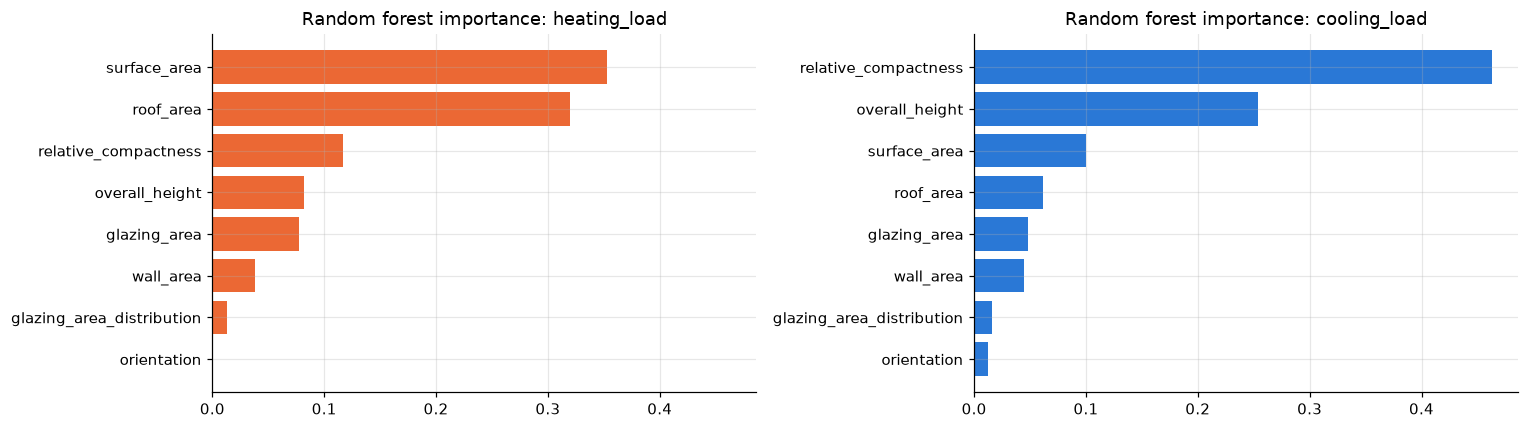

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, target in zip(axes, TARGETS):
    forest = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
    forest.fit(X, y[target])
    importance = pd.Series(forest.feature_importances_, index=FEATURES).sort_values()
    ax.barh(importance.index, importance.values, color=COLORS[target])
    ax.set_title(f"Random forest importance: {target}")
plt.tight_layout()
plt.show()

**Observations**
- The shape-related inputs (compactness / surface area, roof area, height) carry most of the importance.
  Orientation gets almost no importance, in line with the correlation analysis; its effect on the cooling load
  (§3.6) is limited to four shapes and is small next to the effect of height and shape.
- `relative_compactness` and `surface_area` swap places between the two plots. This is expected: they hold the same
  information, so the forest uses whichever one it happens to pick. Add the two together to get their joint importance.
- Unlike the article, `glazing_area` is **not** the top input here. The article uses a different importance measure,
  so this is worth checking (e.g. with permutation importance) and discussing in the report.

## 9. Next steps
See `PROJECT_PLAN.md` for the full plan. The main remaining work:
1. **Unseen shapes (§7):** test dropping the redundant shape inputs (compactness and surface area) for the tree
   models, which caused their failure on shape 0.74 (§7.2).
2. **Which inputs matter, with the tuned models:** permutation importance plus a random "probe" input,
   as the article did, to check the glazing-area disagreement from §8.
3. Try treating `orientation` and `glazing_area_distribution` as categories (one-hot encoding). §3.6 shows that the
   effect of orientation does not go in one direction, so this may help the linear models.
4. Run with `N_REPEATS = 100` for the final numbers, so they match the article's protocol exactly.